## Presentado por:

## Esteban Garcia Otalvaro
## Fabian Andrés Posso Garcia

**1. ESQUEMA DEL REGISTRO DE BIOPOTENCIALES.**

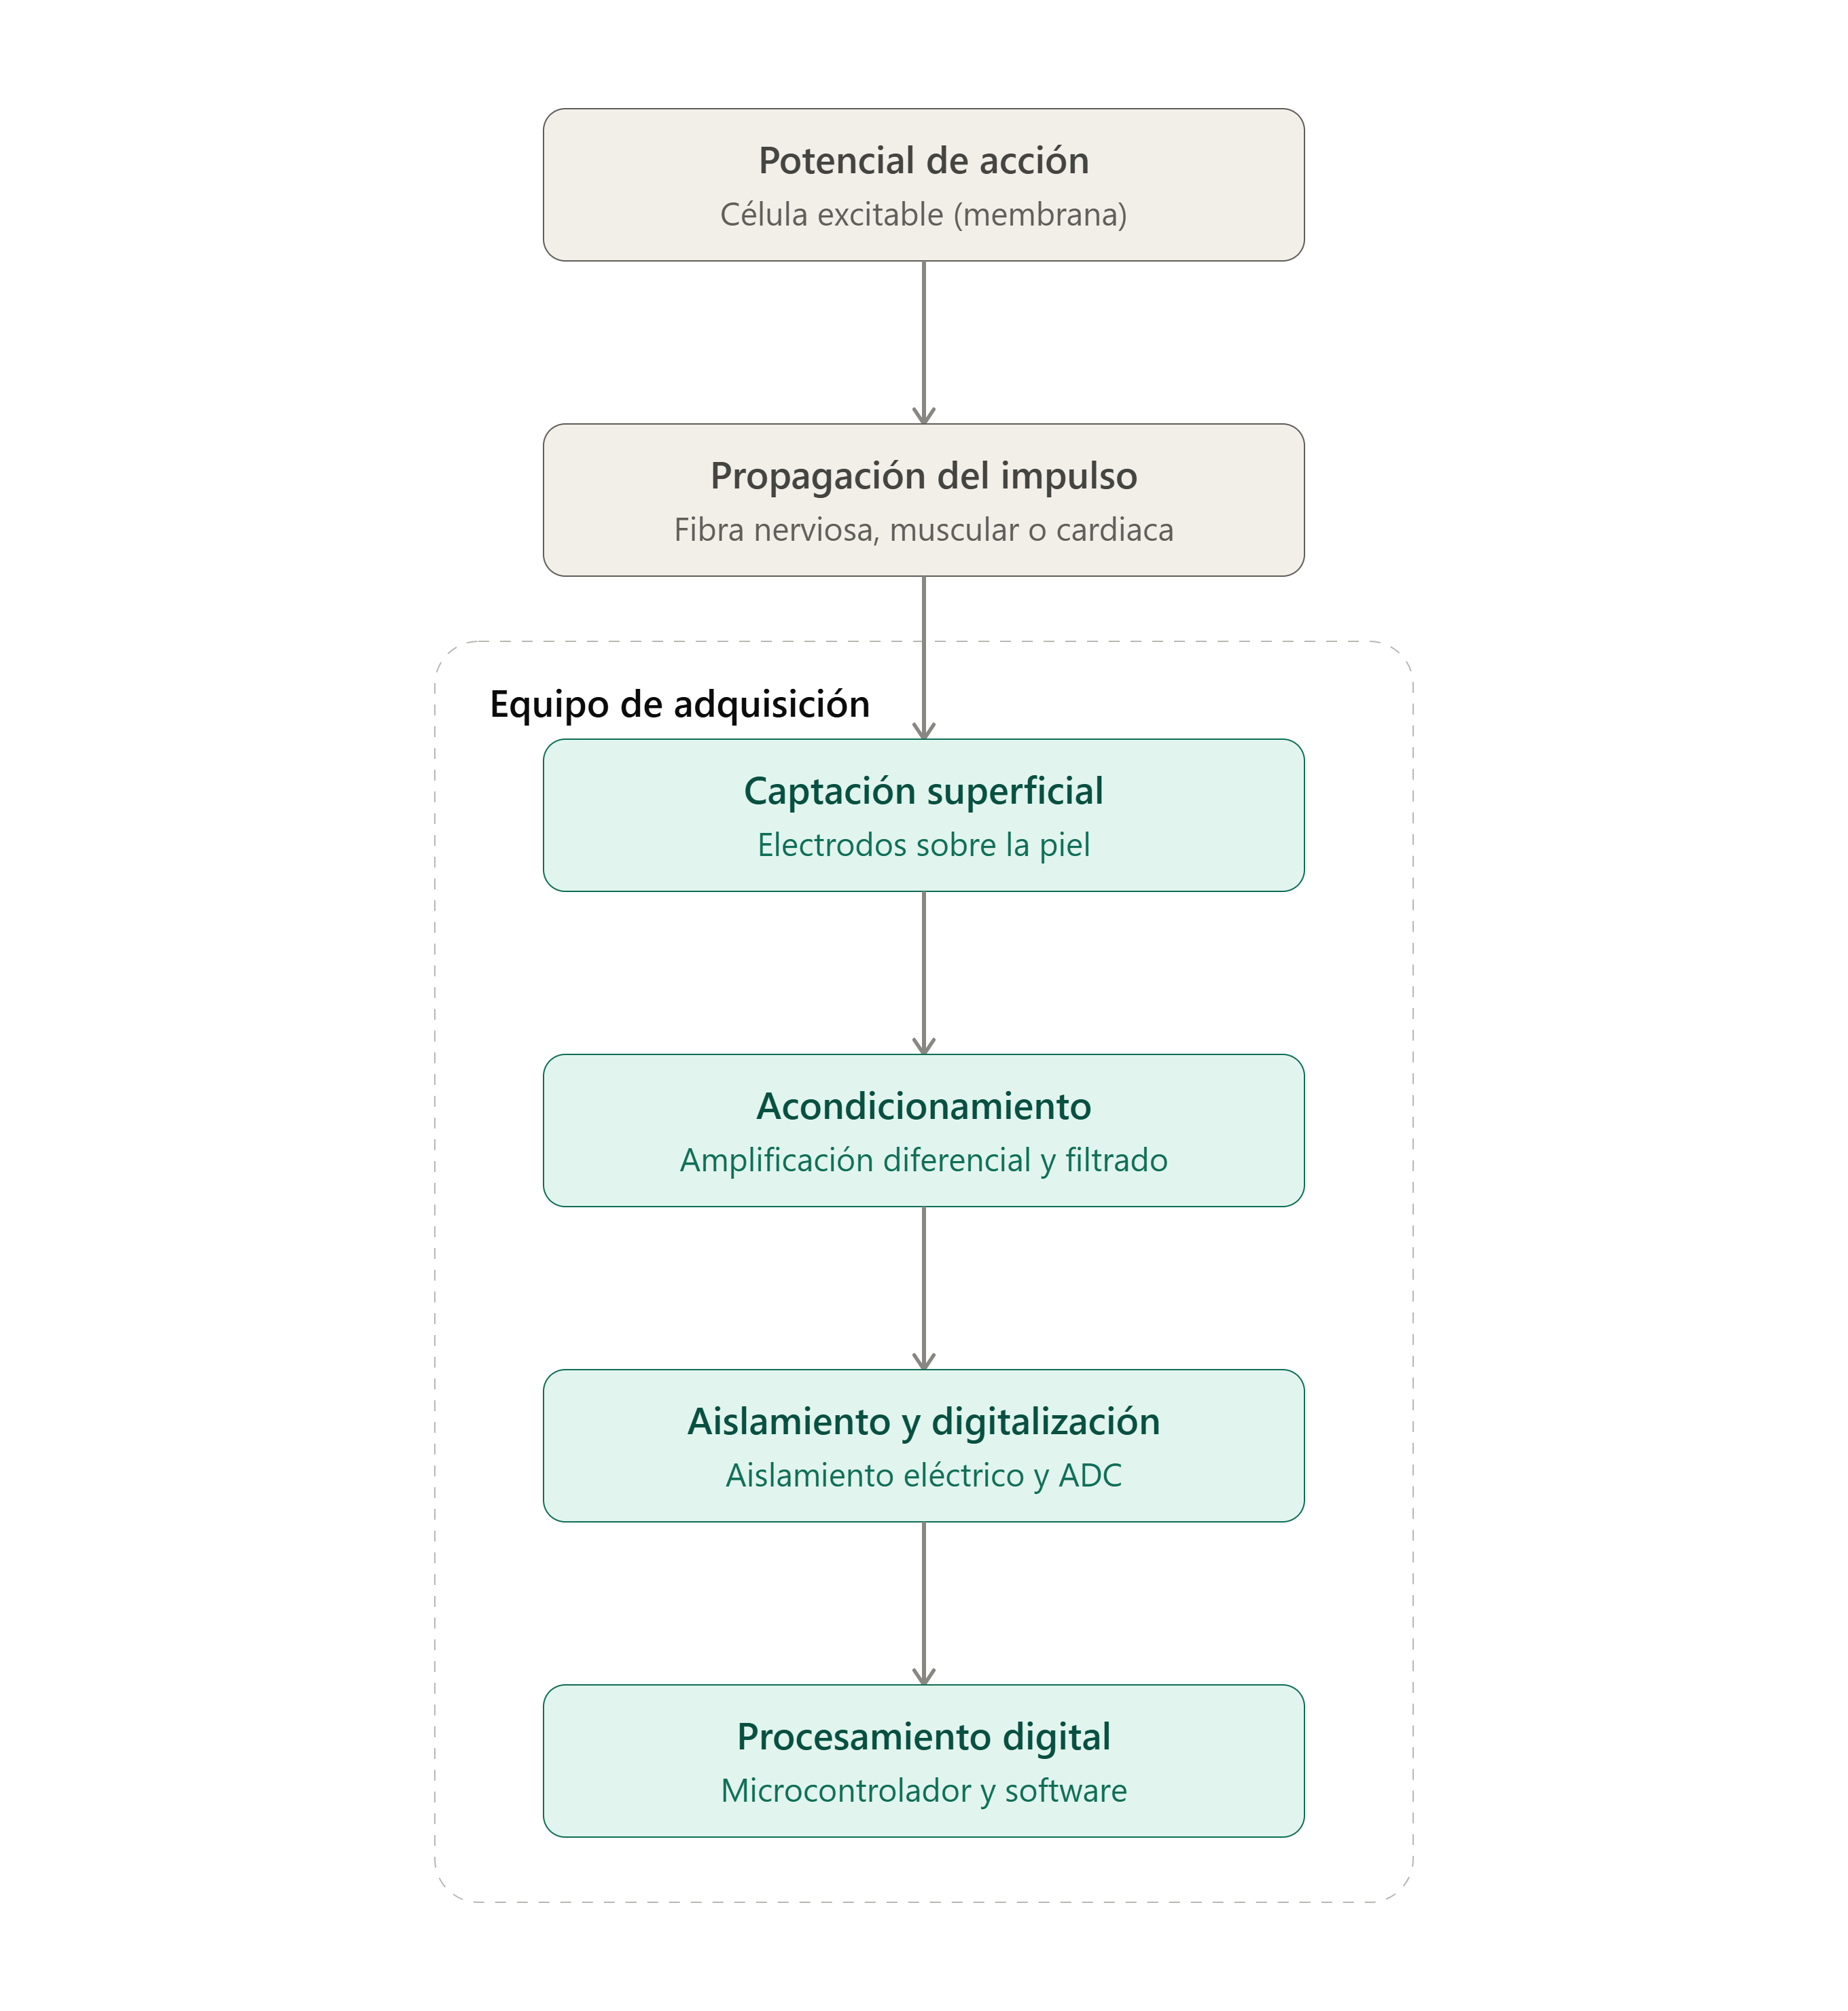

In [19]:
from IPython.display import Image, display

display(Image(filename='esquema_etapas_registro_biopotenciales.png', width=600))

En los dos primeros recuadros se observa lo que ocurre fuera de cualquier instrumento, en el propio tejido:

*Modificación del potencial de membrana en reposo $(-90 \text{ mV})$ a través del flujo de iones ($\text{Na}^+$, $\text{K}^+$, $\text{Ca}^{2+}$) que desencadena potenciales de acción propagados en el miocardio o fibras musculares [1]

*Interfaz Piel-Electrolito-Electrodo: Punto de transducción física donde la corriente iónica hídrica de los tejidos se convierte en flujo de electrones conducido por cables de cobre mediante reacciones de óxido-reducción en electrodos de Ag/AgCl [1], [2].

Posteriormente, el equipo de adquisición (a partir del tercer recuadro) sensa la señal mediante los electrodos en la piel y pasa por cuatro etapas dentro del instrumento que la convierte en digital: 

*Preamplificación Diferencial: Eleva la magnitud de biopotenciales en el rango de microvolts/miliboltios $(\mu\text{V}/\text{mV})$ mediante un amplificador de instrumentación [1].

*Filtrado Analógico: Acota el ancho de banda útil mediante un filtro pasa-alto (elimina el offset DC de media célula) y un filtro pasa-bajo (antialiasing) [2].

*Discretización (ADC mediante bloque ARDUINO UNO/SHIELD-EKG-EMG): Cuantización analógica a digital mediante el convertidor interno de 10 bits del microcontrolador (resolución de $1024$ niveles para un rango dinámico de $0 - 5 \text{ V}$) [2].

*Transmisión y Visualización: Envió serial continuado de las muestras cuantitativas hacia la estación de cómputo para su manipulación en entornos Python [2], [4].

Componentes de un Equipo de Adquisición BiomédicaElectrodos de Superficie (Ag/AgCl): 

*Sensores primarios no polarizables colocados bajo configuraciones estandarizadas (Triángulo de Einthoven para ECG o pares sobre vientres musculares en sEMG) [1], [5].

*Amplificador de Instrumentación: Circuito de alta impedancia de entrada ($> 10^{10} \, \Omega$) diseñado para amplificar la diferencia de potencial biológica reduciendo interferencias ambientales comunes a ambos electrodos [1].

*Filtros Analógicos y Módulo RLD (Right Leg Drive): Módulos dedicados a la supresión de ruido de red eléctrica ($50/60 \text{ Hz}$) y derivas de línea base [1], [2].

*Unidad de Procesamiento y Digitalización: Tarjeta de adquisición (microcontrolador/ADC) acoplada a una interfaz de software para almacenamiento, análisis temporal/espectral y diagnóstico [2], [4].

**2. FUENTES DE RUIDO:**

<table style="width:100%; border-collapse:collapse; margin:15px 0; font-family:sans-serif;">
  <thead>
    <tr style="background-color:#2d3748; color:white; text-align:left;">
      <th style="padding:10px; border:1px solid #4a5568; width:22%;">Fuente de Ruido</th>
      <th style="padding:10px; border:1px solid #4a5568; width:15%;">Naturaleza Temporal</th>
      <th style="padding:10px; border:1px solid #4a5568; width:30%;">Origen Físico / Fisiológico</th>
      <th style="padding:10px; border:1px solid #4a5568; width:33%;">Estrategias de Control o Eliminación</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding:10px; border:1px solid #4a5568;"><b>Grasa Cutánea, Sudor y Aceites</b></td>
      <td style="padding:10px; border:1px solid #4a5568;">Estática / Muy lenta</td>
      <td style="padding:10px; border:1px solid #4a5568;">Secreciones lipídicas y capa de células muertas que incrementan la impedancia superficial de la piel [1].</td>
      <td style="padding:10px; border:1px solid #4a5568;">Limpieza abrasiva previa de la piel frotando con loción de alcohol [1].</td>
    </tr>
    <tr style="background-color:rgba(255,255,255,0.03);">
      <td style="padding:10px; border:1px solid #4a5568;"><b>Interferencia de Red Eléctrica (60 Hz)</b></td>
      <td style="padding:10px; border:1px solid #4a5568;">Variante en el tiempo</td>
      <td style="padding:10px; border:1px solid #4a5568;">Acoplamiento capacitivo/inductivo de líneas de alta tensión o equipos sobre el cuerpo del paciente y cables [1], [2].</td>
      <td style="padding:10px; border:1px solid #4a5568;">Uso de cables apantallados trenzados, alto CMRR en el InAmp, circuito RLD y filtro Notch digital a 60 Hz [1], [2].</td>
    </tr>
    <tr>
      <td style="padding:10px; border:1px solid #4a5568;"><b>Artefactos de Movimiento y Deriva de Línea Base</b></td>
      <td style="padding:10px; border:1px solid #4a5568;">Variante en el tiempo</td>
      <td style="padding:10px; border:1px solid #4a5568;">Desplazamiento mecánico de los electrodos sobre la piel o deformación cutánea por respiración [1].</td>
      <td style="padding:10px; border:1px solid #4a5568;">Fijación física de electrodos, reposo del sujeto y filtrado Pasa-Alto IIR/FIR (0.5 Hz) [1], [4].</td>
    </tr>
    <tr style="background-color:rgba(255,255,255,0.03);">
      <td style="padding:10px; border:1px solid #4a5568;"><b>Interferencia Electromiográfica (EMG) en ECG</b></td>
      <td style="padding:10px; border:1px solid #4a5568;">Variante en el tiempo</td>
      <td style="padding:10px; border:1px solid #4a5568;">Actividad eléctrica involuntaria de músculos esqueléticos cercanos durante el registro [1], [5].</td>
      <td style="padding:10px; border:1px solid #4a5568;">Mantener al paciente en reposo muscular completo y aplicar filtros pasa-bajo suaves [1].</td>
    </tr>
    <tr>
      <td style="padding:10px; border:1px solid #4a5568;"><b>Potencial de Media Célula (DC Offset)</b></td>
      <td style="padding:10px; border:1px solid #4a5568;">Estática / Lenta</td>
      <td style="padding:10px; border:1px solid #4a5568;">Potencial de contacto electroquímico generado en la frontera gel-electrodo/piel [1].</td>
      <td style="padding:10px; border:1px solid #4a5568;">Utilizar electrodos no polarizables de Ag/AgCl y acoplamiento capacitivo en AC [1].</td>
    </tr>
  </tbody>
</table>

**3. ACOPLAMIENTO PIEL-ELECTRODO:**

*Problemática Asociada: El stratum corneum de la piel consiste en células muertas queratinizadas que generan una alta impedancia de entrada ($10 \text{ k}\Omega - 1 \text{ M}\Omega$). Al contacto con el electrodo, la presencia de grasa o sudor incrementa la asimetría de impedancias entre los canales diferenciales, lo que convierte el ruido en modo común (como la red de 60 Hz) en una señal de interferencia diferencial impredecible.   

*Estrategias de Mejora Aplicadas en el Laboratorio: 

**Aseo y Limpieza Cutánea: Frotar rigurosamente la zona con loción de alcohol para remover aceites, grasa y sudor previa colocación.   

**Gel Electrolítico Conductor: Reduce la impedancia al establecer un puente iónico continuo con la piel.

**Uso de Configuraciones Estandarizadas: Posicionamiento correcto según la derivación de Einthoven (RA - clavícula derecha, LA - clavícula izquierda, LL - costado inferior izquierdo) para maximizar la amplitud del complejo QRS.   

*Constituye la etapa más crítica en señales de superficie (sEMG, EEG, ECG) porque es la frontera de transducción entre la corriente iónica biológica y la corriente electrónica del circuito. Cualquier artefacto de movimiento o desbalance en esta interfaz deteriora la señal en la fuente, siendo imposible recuperar la morfología fisiológica real mediante software si el amplificador analógico llega a saturarse.

**4. Análisis de la Variabilidad de la frecuencia cardíaca (HRV):**

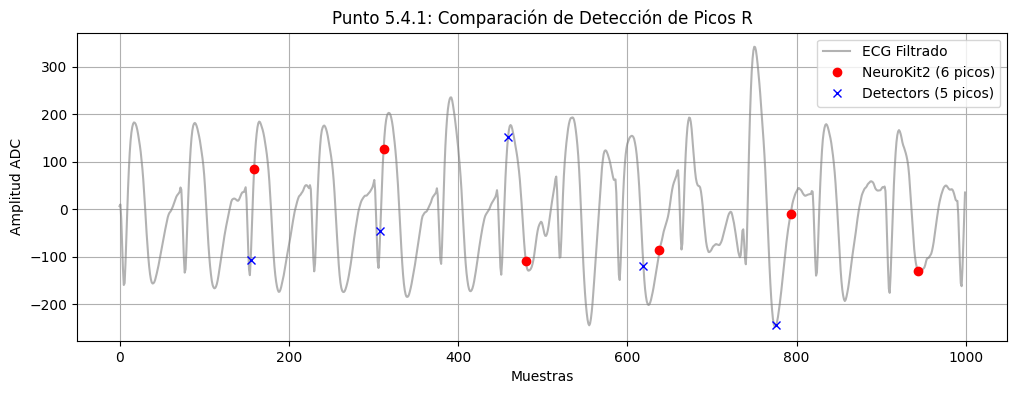

 RESULTADOS DEL PUNTO 5.4.2: CÁLCULO DE HRV
• Total de latidos detectados:       6
• Intervalo R-R promedio (NNI):      314.00 ms
• Frecuencia Cardíaca Promedio:       191.35 BPM
• Variabilidad del intervalo R-R:     de 302.00 ms a 336.00 ms


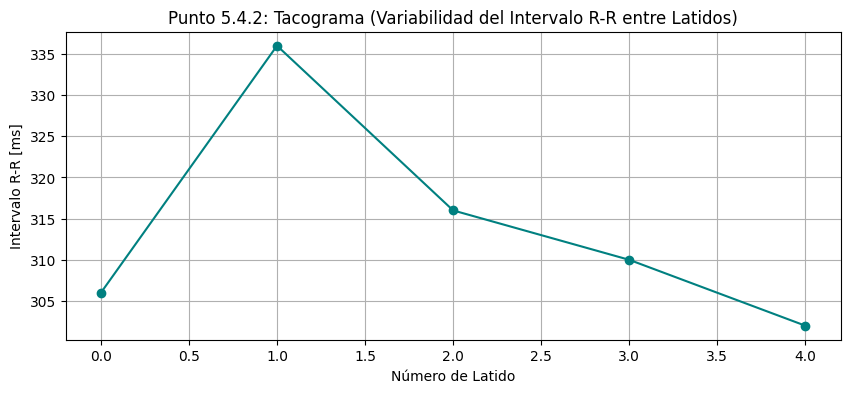

 PUNTO 5.4.3: CARACTERÍSTICAS DE HRV EN EL DOMINIO DEL TIEMPO
       mean_nni: 314.00
           sdnn: 13.34
           sdsd: 18.68
         nni_50: 0.00
        pnni_50: 0.00
         nni_20: 1.00
        pnni_20: 25.00
          rmssd: 18.71
     median_nni: 310.00
      range_nni: 34.00
           cvsd: 0.06
          cvnni: 0.04
        mean_hr: 191.35
         max_hr: 198.68
         min_hr: 178.57
         std_hr: 7.02


In [51]:
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
from ecgdetectors import Detectors
import astropy.stats
import astropy.timeseries
astropy.stats.LombScargle = astropy.timeseries.LombScargle

from hrvanalysis import get_time_domain_features

archivo = 'senal_ecg1.txt'
ecg_signal = np.loadtxt(archivo)
fs = 500  # Frecuencia de muestreo (Hz)

ecg_clean = nk.ecg_clean(ecg_signal, sampling_rate=fs, method="pantompkins")

# PUNTO 5.4.1: DETECCIÓN DE PICOS R (NeuroKit2 vs Detectors)
_, info_nk = nk.ecg_peaks(ecg_clean, sampling_rate=fs, method="pantompkins")
peaks_neurokit = info_nk["ECG_R_Peaks"]

detectors = Detectors(fs)
peaks_detectors = np.array(detectors.pan_tompkins_detector(ecg_clean))

# Gráfica de detección
plt.figure(figsize=(12, 4))
plt.plot(ecg_clean, label="ECG Filtrado", color="gray", alpha=0.6)
plt.plot(peaks_neurokit, ecg_clean[peaks_neurokit], "ro", label=f"NeuroKit2 ({len(peaks_neurokit)} picos)")
plt.plot(peaks_detectors, ecg_clean[peaks_detectors], "bx", label=f"Detectors ({len(peaks_detectors)} picos)")
plt.title("Punto 5.4.1: Comparación de Detección de Picos R")
plt.xlabel("Muestras")
plt.ylabel("Amplitud ADC")
plt.legend(loc="upper right")
plt.grid(True)
plt.show()

# PUNTO 5.4.2: RESULTADO DEL CÁLCULO DE HRV (TACOGRAMA Y VALORES BASE)

# A. Intervalos R-R en milisegundos (Diferencia de tiempo entre picos)
rr_intervals_ms = np.diff(peaks_neurokit) / fs * 1000.0

# B. Frecuencia cardíaca instantánea en BPM
bpm_instantaneo = 60000.0 / rr_intervals_ms

print("="*60)
print(" RESULTADOS DEL PUNTO 5.4.2: CÁLCULO DE HRV")
print("="*60)
print(f"• Total de latidos detectados:       {len(peaks_neurokit)}")
print(f"• Intervalo R-R promedio (NNI):      {np.mean(rr_intervals_ms):.2f} ms")
print(f"• Frecuencia Cardíaca Promedio:       {np.mean(bpm_instantaneo):.2f} BPM")
print(f"• Variabilidad del intervalo R-R:     de {np.min(rr_intervals_ms):.2f} ms a {np.max(rr_intervals_ms):.2f} ms")

# C. Gráfica del Tacograma (Resultado visual directo de HRV)
plt.figure(figsize=(10, 4))
plt.plot(rr_intervals_ms, marker='o', color='teal', linestyle='-', linewidth=1.5)
plt.title("Punto 5.4.2: Tacograma (Variabilidad del Intervalo R-R entre Latidos)")
plt.xlabel("Número de Latido")
plt.ylabel("Intervalo R-R [ms]")
plt.grid(True)
plt.show()

# PUNTO 5.4.3: CARACTERÍSTICAS EXTRAÍDAS CON HRVANALYSIS

rr_list = [float(x) for x in rr_intervals_ms if not np.isnan(x) and x > 0]
hrv_features = get_time_domain_features(rr_list)

print("="*60)
print(" PUNTO 5.4.3: CARACTERÍSTICAS DE HRV EN EL DOMINIO DEL TIEMPO")
print("="*60)
for metric, val in hrv_features.items():
    print(f"{metric:>15}: {val:.2f}")

¿Cuál algoritmo detecta mejor los picos R?

1. **NeuroKit2 (`nk.ecg_peaks`):** Demuestra un desempeño **superior y más estable** frente a artefactos de movimiento y fluctuaciones de la línea base típicas de la tarjeta Olimex/Arduino. Incorpora un filtrado adaptativo previo que evita la detección de falsos positivos en ondas T prominentes o picos de ruido.

2. **`Detectors` (`ecgdetectors.Detectors`):** Aunque el detector Pan-Tompkins de esta librería funciona de forma adecuada en señales clínicas limpias, tiende a perder picos R en tramos con baja relación señal-ruido ($\text{SNR}$) o a duplicar marcas en presencia de deriva de línea base.

**Conclusión:** El algoritmo implementado por **NeuroKit2** es más robusto y adecuado para el procesamiento de las bioseñales adquiridas en esta práctica.

**5. Aplicaciones clinicas de ECG y EMG:**

*Aplicaciones del Electrocardiograma (ECG):

**Detección de Arritmias Cardíacas (ej. Fibrilación Auricular):

-Registro: Monitoreo continuo mediante Holter de 24 horas.   
-Procesamiento: Detección de la variabilidad del intervalo R-R y análisis espectral de ausencia de onda P.   

**Diagnóstico de Isquemia e Infarto de Miocardio:

-Registro: ECG de 12 derivaciones en reposo o prueba de esfuerzo.   
-Procesamiento: Promediado por bloques (ensembles) e inspección de elevación/depresión del segmento ST.   

**Monitoreo de Cardiotoxicidad Fármaco-inducida (Intervalo QTc):

-Registro: Telemetría electrocardiográfica en Cuidados Intensivos (UCI).   
-Procesamiento: Algoritmos de delineamiento automático del inicio de Q y final de onda T con corrección de Bazett.  

*Aplicaciones del Electromiograma (EMG):

**Control Prostético de Miembro Superior (Miotécnico):

-Registro: sEMG multicanal sobre músculos antagonistas del muñón (ej. flexores/extensores).   
-Procesamiento: Rectificación de onda completa, cálculo de la envolvente RMS e identificación de intenciones de agarre.   

**Evaluación de Fatiga Muscular en Biomecánica Laboral:

-Registro: sEMG durante contracciones isométricas sostenidas.   
-Procesamiento: Transformada de Fourier en tiempo corto (STFT) para evaluar la compresión del espectro hacia frecuencias bajas (caída de la Frecuencia Mediana - MDF).   

**Diagnóstico de Miopatías y Neuropatías Periféricas:

-Registro: EMG intramuscular (con aguja) en reposo y contracción voluntaria.   
-Procesamiento: Análisis morfométrico de los Potenciales de Acción de Unidad Motora (MUAP).   

**6. CONCLUSIONES.**

-Rol crítico del acondicionamiento analógico: La combinación del módulo SHIELD-EKG-EMG con la etapa de conversión del ARDUINO UNO demuestra que una adecuada relación de rechazo al modo común (CMRR) y filtrado de banda analógico es esencial para rescatar biopotenciales del orden de microvolts frente al ruido ambiental

-Impacto de la preparación cutánea: El frotado con alcohol es una etapa insustituible para atenuar la alta impedancia del estrato córneo y eliminar secreciones de grasa/sudor, previniendo la deriva de línea base y la descalibración del offset en el registro.   

-Sinergia hardware-software: Mientras que el hardware asegura la integridad eléctrica inicial de la bioseñal, las librerías computacionales (NeuroKit2, hrvanalysis) permiten aislar parámetros cuantitativos clave como la HRV y patrones de contracción muscular para uso en diagnóstico clínico o control prostético. 

-Preservación de la señal original: La configuración de alta impedancia de entrada en la primera etapa es indispensable en la bioinstrumentación, ya que evita el efecto de carga y garantiza que los biopotenciales de baja amplitud captados por los electrodos no sufran atenuación ni distorsión al ingresar al sistema.

-Aislamiento del biopotencial: La estructura diferencial de la segunda etapa resulta crítica para garantizar la calidad de los datos, pues su alto rechazo en modo común (CMRR) es el mecanismo principal para suprimir el ruido eléctrico externo (como la interferencia de 60 Hz) que enmascara las señales fisiológicas.

-Adaptabilidad para la digitalización: El diseño ofrece una integración eficiente con sistemas modernos de adquisición de datos y microcontroladores. La capacidad de ajustar la ganancia global con una sola resistencia ($R_G$) y de adaptar el nivel DC mediante el terminal de referencia ($V_{ref}$) facilita la transición de la señal analógica a los rangos de voltaje estrictamente positivos requeridos por los conversores ADC.



**REFERENCIAS:**

* **[1]** J. G. Webster, Ed., *Medical Instrumentation: Application and Design*, 4th ed. Hoboken, NJ, USA: John Wiley & Sons, 2009.
* **[2]** J. Moore y G. Zouridakis, Eds., *Biomedical Technology and Devices Handbook*. Boca Raton, FL, USA: CRC Press LLC, 2004.
* **[3]** J. D. Bronzino, Ed., *The Biomedical Engineering Handbook*, 2nd ed. Boca Raton, FL, USA: CRC Press LLC, 2000.
* **[4]** J. Pan y W. J. Tompkins, "A real-time QRS detection algorithm," *IEEE Transactions on Biomedical Engineering*, vol. BME-32, no. 3, pp. 230–236, Mar. 1985.
* **[5]** C. J. De Luca, "The use of surface electromyography in biomechanics," *Journal of Applied Biomechanics*, vol. 13, no. 2, pp. 135–163, 1997.
* **[6]** Task Force of the European Society of Cardiology and the North American Society of Pacing and Electrophysiology, "Heart rate variability: Standards of measurement, physiological interpretation, and clinical use," *Circulation*, vol. 93, no. 5, pp. 1043–1065, Mar. 1996.